# Grocery Product Demand Analysis
**Course:** Exploratory Data Analysis and Visualization (EDAV)  
**Dataset:** Supermarket Sales CSV  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

## Objective
Explore transaction-level supermarket sales to understand product-line demand, branch performance, customer spending, time patterns, and payment preferences. Fill in your name, roll number, department, and submission date.

**Dataset limitation:** This dataset supports descriptive analysis of transactions and quantity sold. It does not include inventory or stockout data, so it cannot measure unmet demand or provide a reliable inventory forecast.

## 1. Load the single CSV file
Set `DATA_PATH` to the exact path of your downloaded CSV. This notebook does not use a ZIP file or a manual upload dialog.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# If the file is in Colab's sample_data folder, use this path:
DATA_PATH = "/content/supermarket_sales.csv"

# If it is in Google Drive, mount Drive and replace the path above:
# from google.colab import drive
# drive.mount("/content/drive")
# DATA_PATH = "/content/drive/MyDrive/supermarket_sales.csv"

if not os.path.isfile(DATA_PATH):
    raise FileNotFoundError(f"CSV not found: {DATA_PATH}. Update DATA_PATH to the exact file location.")
df = pd.read_csv(DATA_PATH)
print("Rows:", len(df), " Columns:", len(df.columns))
display(df.head())

Rows: 1000  Columns: 17


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


## 2. Inspect and understand the dataset

In [ ]:
print("Columns:", df.columns.tolist())
df.info()
display(df.describe(include="all").T)
print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("Missing values"))
print("Duplicate rows:", df.duplicated().sum())

Columns: ['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null   float64
 10  Date                   

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Invoice ID,1000,1000,849-09-3807,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Branch,1000,3,A,340,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,1000,3,Yangon,340,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer type,1000,2,Member,501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,1000,2,Female,501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product line,1000,6,Fashion accessories,178,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Unit price,1000.0,NaN,NaN,NaN,55.67213,26.494628,10.08,32.875,55.23,77.935,99.96
Quantity,1000.0,NaN,NaN,NaN,5.51,2.923431,1.0,3.0,5.0,8.0,10.0
Tax 5%,1000.0,NaN,NaN,NaN,15.379369,11.708825,0.5085,5.924875,12.088,22.44525,49.65
Total,1000.0,NaN,NaN,NaN,322.966749,245.885335,10.6785,124.422375,253.848,471.35025,1042.65



Missing values:


,Missing values
Invoice ID,0
Branch,0
City,0
Customer type,0
Gender,0
Product line,0
Unit price,0
Quantity,0
Tax 5%,0
Total,0


Duplicate rows: 0


## 3. Data cleaning and preparation

In [ ]:
df = df.drop_duplicates().copy()
if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
if "Time" in df.columns:
    parsed_time = pd.to_datetime(df["Time"], format="%H:%M", errors="coerce")
    df["Hour"] = parsed_time.dt.hour
for col in ["Unit price", "Quantity", "Tax 5%", "Total", "cogs", "gross margin percentage", "gross income", "Rating"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
print("Shape after duplicate removal:", df.shape)
display(df.isna().sum().to_frame("Missing values"))

Shape after duplicate removal: (1000, 18)


,Missing values
Invoice ID,0
Branch,0
City,0
Customer type,0
Gender,0
Product line,0
Unit price,0
Quantity,0
Tax 5%,0
Total,0


## 4. General EDA: distributions of sales, quantity, rating, and income

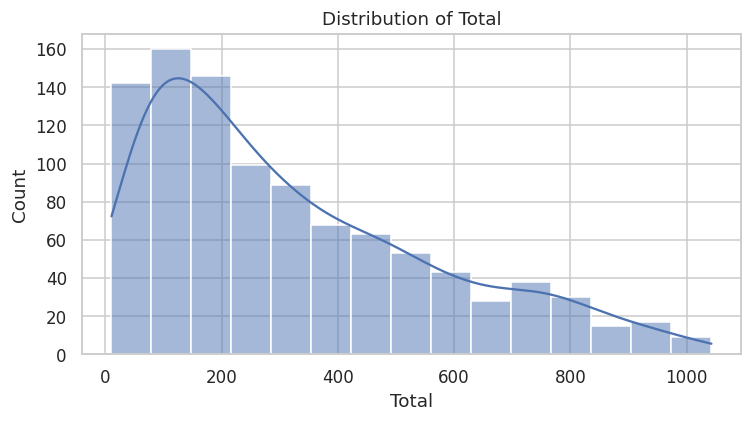

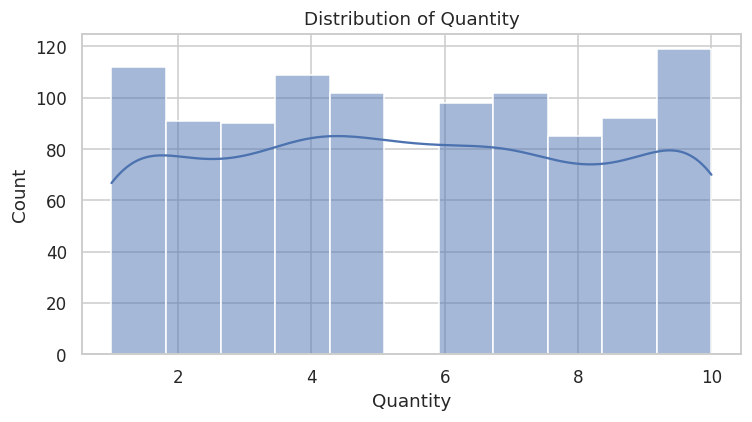

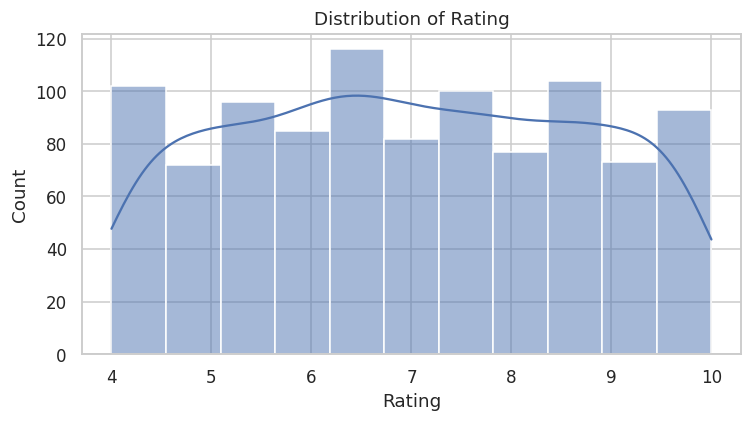

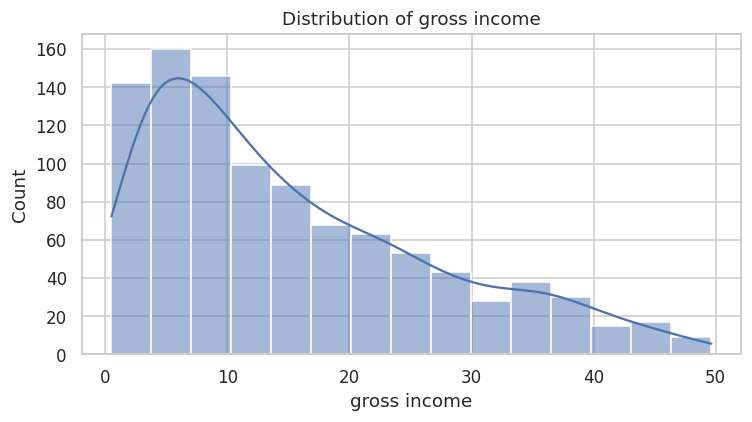

In [ ]:
for col in ["Total", "Quantity", "Rating", "gross income"]:
    if col in df.columns:
        plt.figure(figsize=(7, 4))
        sns.histplot(df[col].dropna(), kde=True)
        plt.title(f"Distribution of {col}")
        plt.tight_layout()
        plt.show()

## 5. Question-wise analysis
The following questions are mapped to CO/BL levels for the course project. Confirm the exact mapping required by your instructor.

### Question 1 [CO1, BL3]: Which product lines have the highest quantity sold and total sales?

,Total_Quantity,Total_Sales,Average_Transaction,Transactions
Product line,,,,
Electronic accessories,971,54337.53,319.63,170
Food and beverages,952,56144.84,322.67,174
Sports and travel,920,55122.83,332.07,166
Home and lifestyle,911,53861.91,336.64,160
Fashion accessories,902,54305.90,305.09,178
Health and beauty,854,49193.74,323.64,152


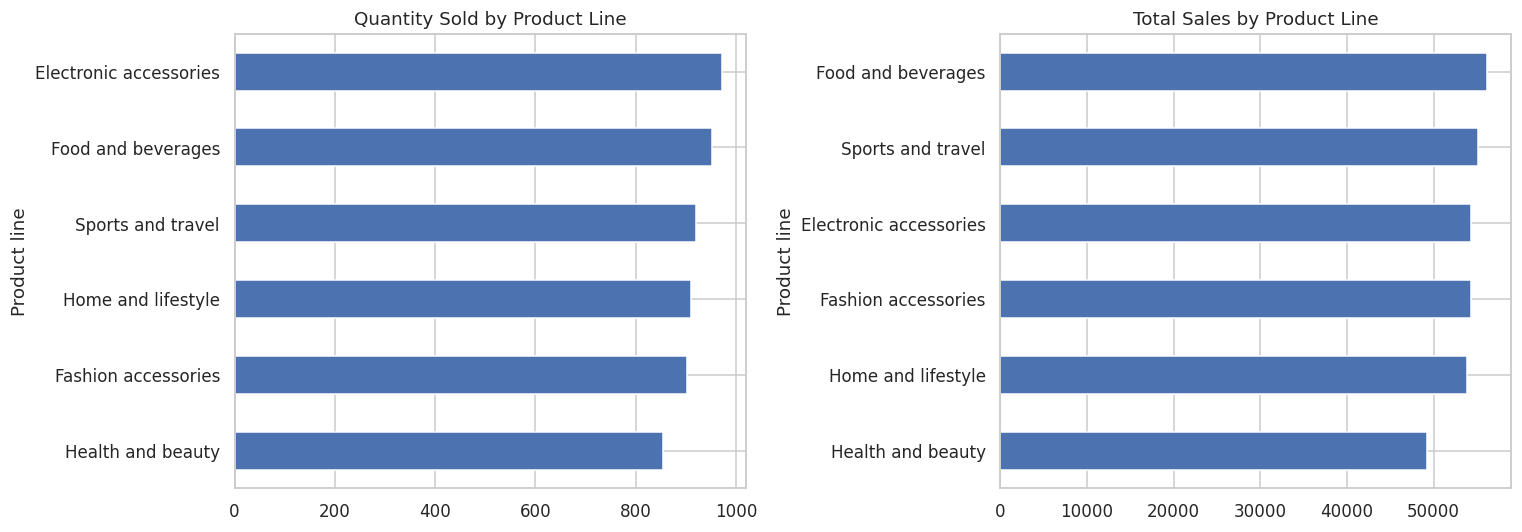

In [ ]:
if {"Product line", "Quantity", "Total"}.issubset(df.columns):
    product_summary = df.groupby("Product line").agg(
        Total_Quantity=("Quantity", "sum"), Total_Sales=("Total", "sum"),
        Average_Transaction=("Total", "mean"), Transactions=("Total", "size")
    ).sort_values("Total_Quantity", ascending=False)
    display(product_summary.round(2))
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    product_summary["Total_Quantity"].sort_values().plot.barh(ax=ax[0], title="Quantity Sold by Product Line")
    product_summary["Total_Sales"].sort_values().plot.barh(ax=ax[1], title="Total Sales by Product Line")
    plt.tight_layout(); plt.show()
else:
    print("Required columns missing. Check df.columns.tolist().")

### Question 2 [CO2, BL3]: How do sales and quantity vary across branches?

,Total_Sales,Total_Quantity,Transactions
Branch,,,
C,110568.71,1831,328
A,106200.37,1859,340
B,106197.67,1820,332


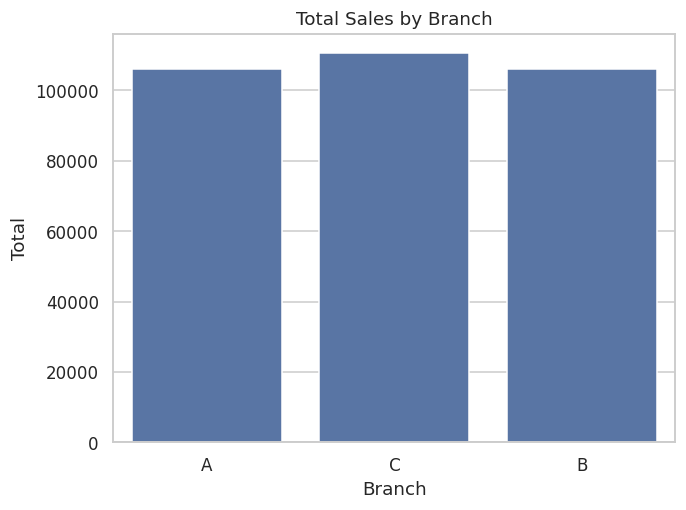

In [ ]:
if {"Branch", "Total", "Quantity"}.issubset(df.columns):
    branch_summary = df.groupby("Branch").agg(Total_Sales=("Total", "sum"), Total_Quantity=("Quantity", "sum"), Transactions=("Total", "size")).sort_values("Total_Sales", ascending=False)
    display(branch_summary.round(2))
    sns.barplot(data=df, x="Branch", y="Total", estimator=sum, errorbar=None)
    plt.title("Total Sales by Branch"); plt.tight_layout(); plt.show()
else:
    print("Branch/Total/Quantity column missing.")

### Question 3 [CO3, BL4]: Do average transaction totals differ by customer type and gender?

Transactions  Average_Spend  Total_Sales
Customer type Gender                                          
Member        Female           261         337.73     88146.94
              Male             240         316.99     76076.50
Normal        Female           240         332.23     79735.98
              Male             259         305.05     79007.32

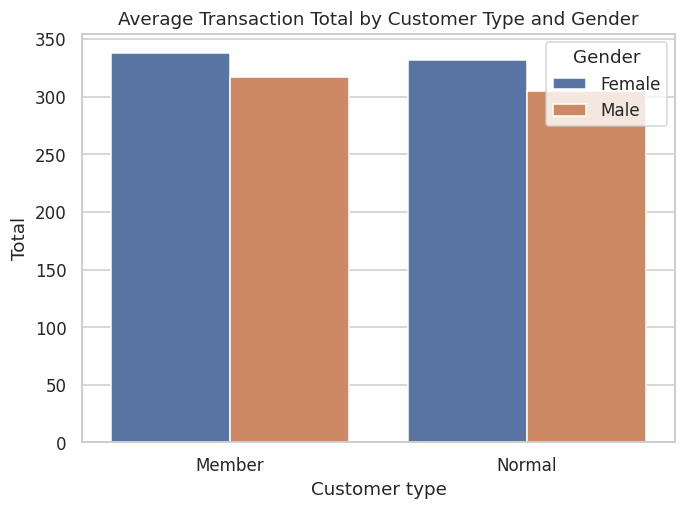

In [ ]:
if {"Customer type", "Gender", "Total"}.issubset(df.columns):
    summary = df.groupby(["Customer type", "Gender"]).agg(Transactions=("Total", "size"), Average_Spend=("Total", "mean"), Total_Sales=("Total", "sum")).round(2)
    display(summary)
    sns.barplot(data=df, x="Customer type", y="Total", hue="Gender", errorbar=None)
    plt.title("Average Transaction Total by Customer Type and Gender"); plt.tight_layout(); plt.show()
else:
    print("Customer type/Gender/Total column missing.")

### Question 4 [CO4, BL4]: How do sales and transaction counts vary by date and hour?

,Daily_Sales,Transactions
Date,,
2019-01-01,4745.1810,12
2019-01-02,1945.5030,8
2019-01-03,2078.1285,8
2019-01-04,1623.6885,6
2019-01-05,3536.6835,12


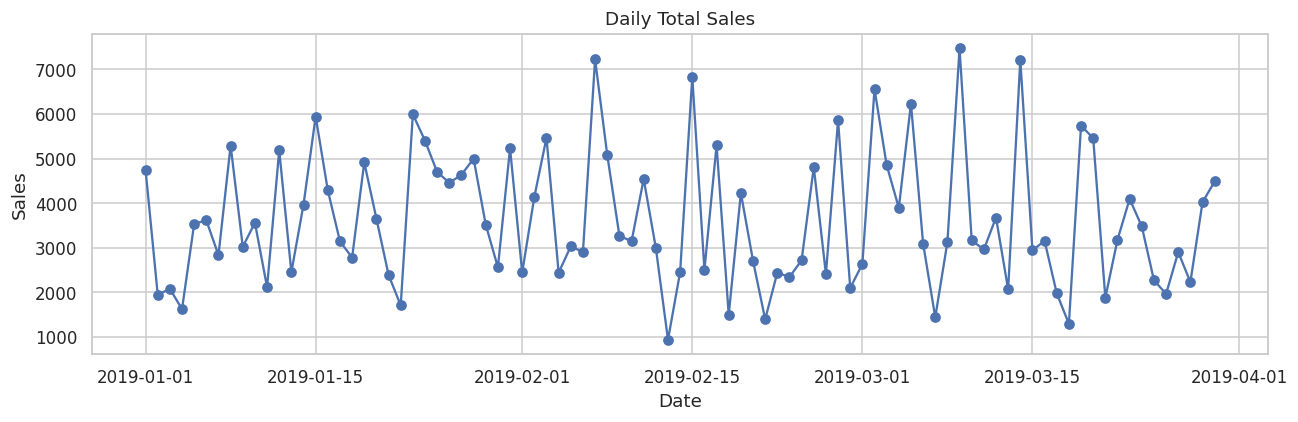

,Transactions,Sales
Hour,,
10,101,31421.4810
11,90,30377.3295
12,89,26065.8825
13,103,34723.2270
14,83,30828.3990
15,102,31179.5085
16,77,25226.3235
17,74,24445.2180
18,93,26030.3400


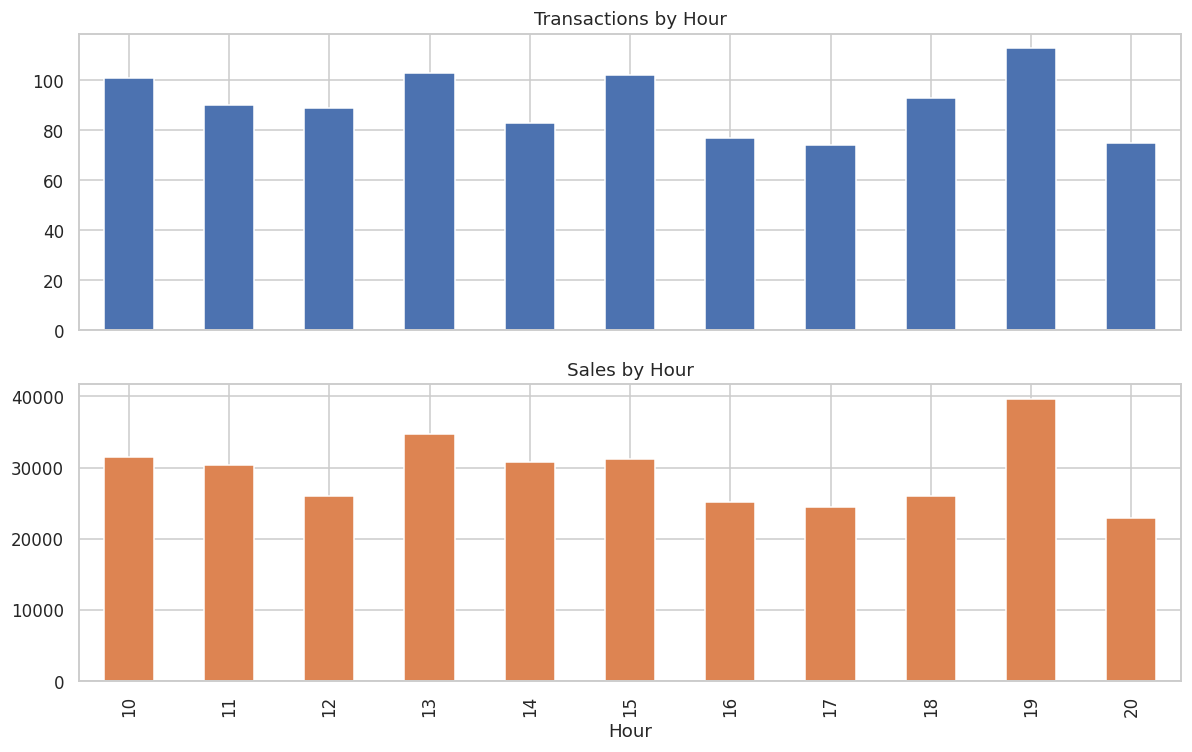

In [ ]:
if {"Date", "Total"}.issubset(df.columns):
    daily = df.dropna(subset=["Date"]).groupby(df["Date"].dt.date).agg(Daily_Sales=("Total", "sum"), Transactions=("Total", "size"))
    display(daily.head())
    daily["Daily_Sales"].plot(figsize=(12, 4), marker="o")
    plt.title("Daily Total Sales"); plt.ylabel("Sales"); plt.tight_layout(); plt.show()
if {"Hour", "Total"}.issubset(df.columns) and df["Hour"].notna().any():
    hourly = df.groupby("Hour").agg(Transactions=("Total", "size"), Sales=("Total", "sum"))
    display(hourly)
    hourly.plot(kind="bar", subplots=True, figsize=(11, 7), legend=False, title=["Transactions by Hour", "Sales by Hour"])
    plt.tight_layout(); plt.show()

### Question 5 [CO5, BL5]: Which payment methods are most used, and how do sales compare?

,Transactions,Total_Sales,Average_Transaction
Payment,,,
Ewallet,345,109993.11,318.82
Cash,344,112206.57,326.18
Credit card,311,100767.07,324.01


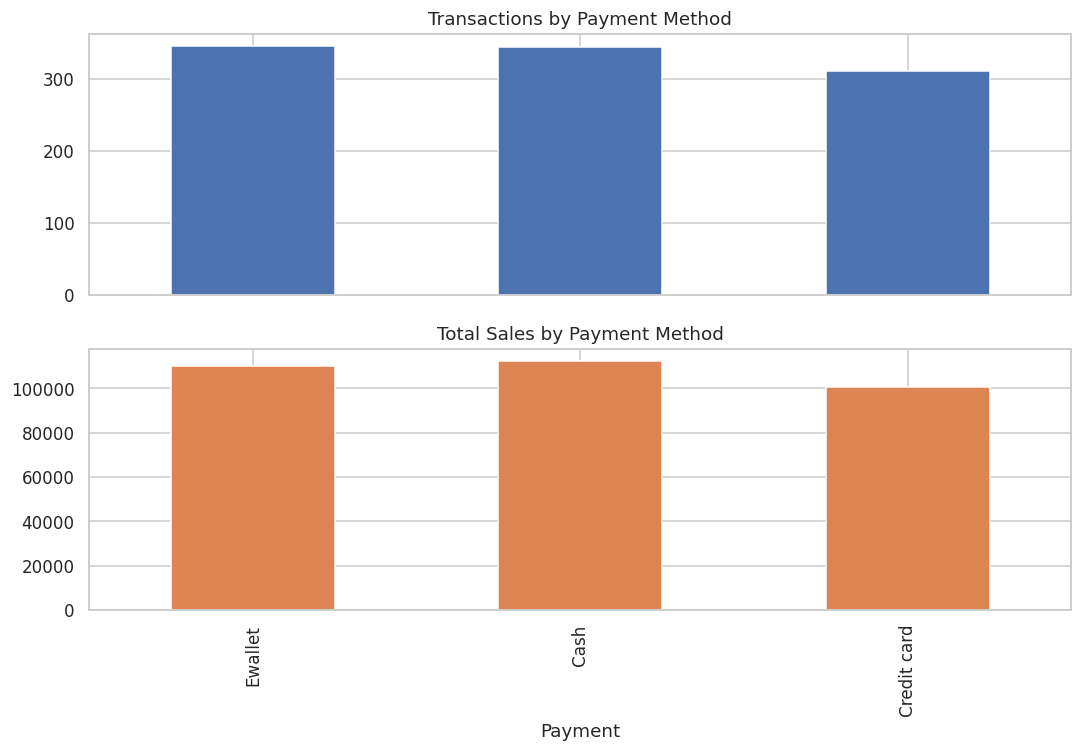

In [ ]:
if {"Payment", "Total"}.issubset(df.columns):
    payment_summary = df.groupby("Payment").agg(Transactions=("Total", "size"), Total_Sales=("Total", "sum"), Average_Transaction=("Total", "mean")).sort_values("Transactions", ascending=False).round(2)
    display(payment_summary)
    payment_summary[["Transactions", "Total_Sales"]].plot(kind="bar", subplots=True, figsize=(10, 7), legend=False, title=["Transactions by Payment Method", "Total Sales by Payment Method"])
    plt.tight_layout(); plt.show()
else:
    print("Payment or Total column missing.")

## 6. Correlation analysis

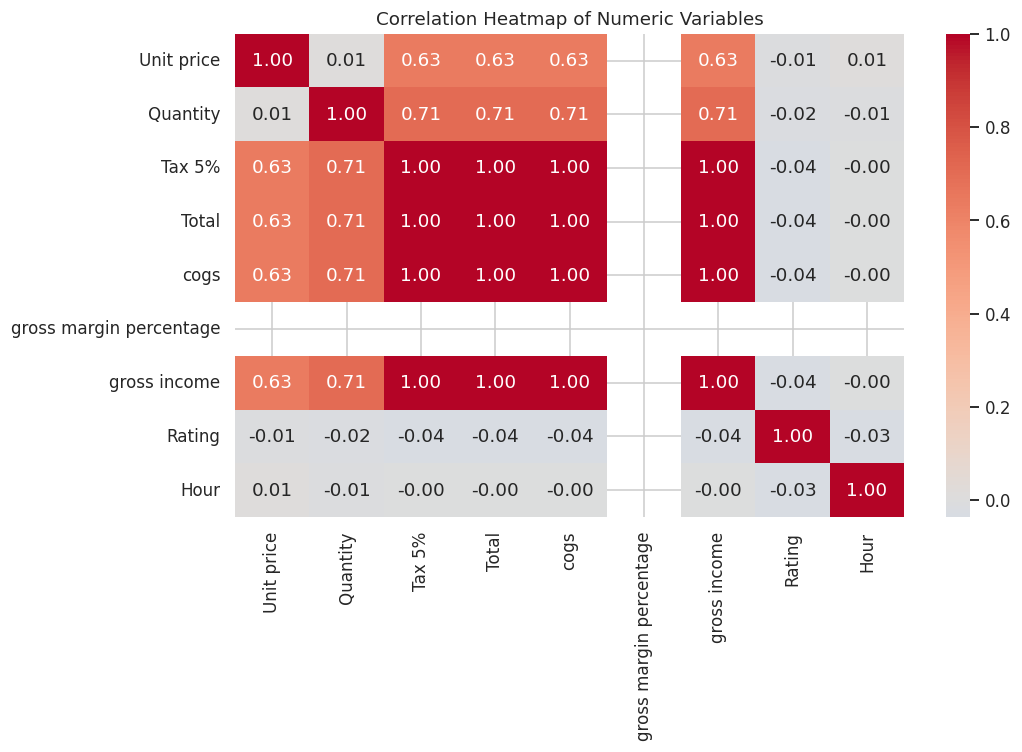

In [ ]:
numeric_df = df.select_dtypes(include=np.number)
if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation Heatmap of Numeric Variables")
    plt.tight_layout(); plt.show()
else:
    print("Not enough numeric columns for correlation analysis.")

## 7. Automatically generated key findings

In [ ]:
if {"Product line", "Quantity", "Total"}.issubset(df.columns):
    q = df.groupby("Product line")["Quantity"].sum().sort_values(ascending=False)
    s = df.groupby("Product line")["Total"].sum().sort_values(ascending=False)
    print(f"Highest quantity product line: {q.index[0]} ({q.iloc[0]:,.0f} units)")
    print(f"Highest sales product line: {s.index[0]} ({s.iloc[0]:,.2f})")
if {"Branch", "Total"}.issubset(df.columns):
    b = df.groupby("Branch")["Total"].sum().sort_values(ascending=False)
    print(f"Highest sales branch: {b.index[0]} ({b.iloc[0]:,.2f})")
if {"Payment", "Total"}.issubset(df.columns):
    p = df["Payment"].value_counts()
    print(f"Most common payment method: {p.index[0]} ({p.iloc[0]} transactions)")

Highest quantity product line: Electronic accessories (971 units)
Highest sales product line: Food and beverages (56,144.84)
Highest sales branch: C (110,568.71)
Most common payment method: Ewallet (345 transactions)


## 8. Results, conclusion, and recommendations
After running all cells, write your interpretation using the actual tables and charts. Include: (1) strongest product lines by quantity and sales, (2) differences across branches, (3) observed customer spending differences, (4) peak observed date/hour patterns, and (5) most common payment method. Recommendations should be supported by the results.

**Limitations:** The dataset has a limited transaction history and lacks inventory, stockout, and customer-level longitudinal data. Findings describe observed sales; they do not prove causes or forecast future demand.

## 9. References
1. Dataset page: https://www.kaggle.com/datasets/aungpyaeap/supermarket-sales
2. Pandas documentation: https://pandas.pydata.org/docs/
3. Matplotlib documentation: https://matplotlib.org/stable/
4. Seaborn documentation: https://seaborn.pydata.org/

## Troubleshooting
- `FileNotFoundError`: update `DATA_PATH` to the actual location and exact filename.
- If the CSV columns differ, run `print(df.columns.tolist())` and update the relevant column names.
- Run cells from top to bottom after setting the correct path.